# 3. 🎨 Control where color lands

[All tutorials](https://github.com/bateni1380/landpy/tree/master/tutorials) · [Open in Colab](https://colab.research.google.com/github/bateni1380/landpy/blob/master/tutorials/3-heat-maps-and-filters.ipynb)

## Goal

Turn landmarks into a soft mask and blend a color into only that region. By the end, you can explain how mask strength and filter ratio work together—the same idea we use for lip color in notebook 8.

## Setup

Run all cells from top to bottom in a fresh kernel. The setup cell installs Landpy 0.1.1 if needed. A CPU is enough. Python 3.10+ is supported; no model downloads are needed here.

In [1]:
import importlib.metadata
import subprocess
import sys
try:
    installed = importlib.metadata.version('landpy')
except importlib.metadata.PackageNotFoundError:
    installed = None
if installed != '0.1.1':
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'landpy==0.1.1'])
import numpy as np
from landpy import ImageLand, MarksLand, SquareMarks, Filter, Debugger


## Steps

### 1. Rasterize a polygon

A HeatLand is a finite 2D float array in [0, 1]. Polygon points use the same row/column order as images.

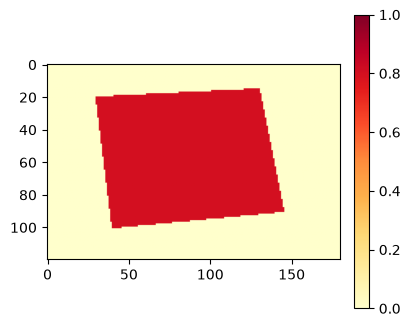

In [2]:
rows, columns = np.indices((120, 180))
pixels = np.stack((columns / 179, rows / 119, np.full(rows.shape, .35)), axis=-1)
image = ImageLand(pixels)

polygon = MarksLand([[20, 30], [15, 130], [90, 145], [100, 40]], shape=image.shape)
heat = polygon.to_heat(.8)
heat.show();

### 2. Use the original heat algebra

`a + b` means maximum (union), `a - b` means minimum (intersection), and `-a` means complement. Subtraction is deliberately **not arithmetic difference**. Scale and power change mask strength; scales clip to [0, 1]. Shapes must match for binary operations.

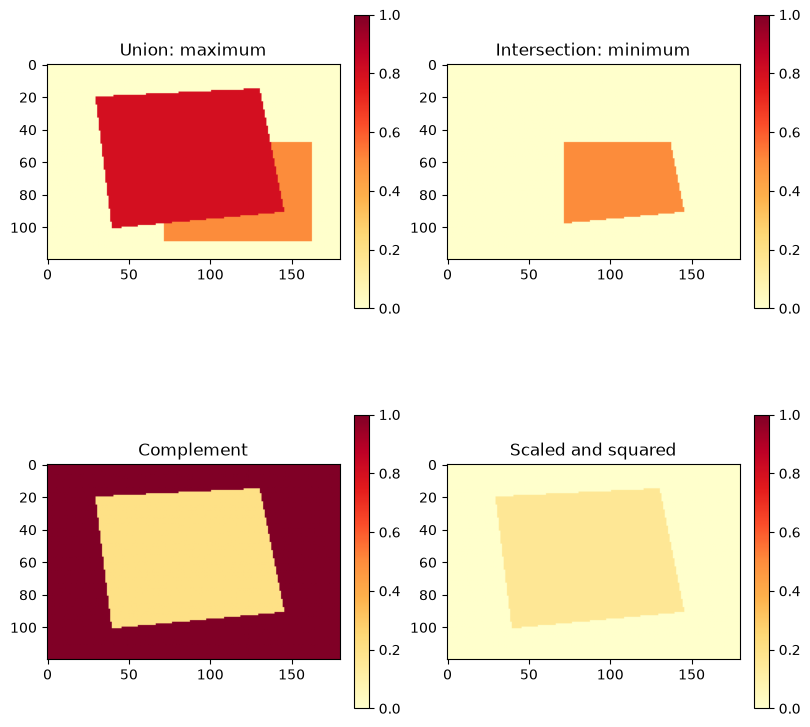

In [3]:
other = SquareMarks.relative(.4, .9, .4, .9, shape=image.shape).to_heat(.5)
heats = [heat + other, heat - other, -heat, (.5 * heat)**2]
debugger = Debugger(visual_debug=True)
debugger.log_images(
    [item.get_heat() for item in heats],
    ['Union: maximum', 'Intersection: minimum', 'Complement', 'Scaled and squared'],
    [Debugger.LogTypes.HEAT] * 4, dim=(2, 2),
);

### 3. Apply a color or custom function

`Filter` blends toward an RGB color using `ratio * heat`. A different-size mask is resized on a copy. Alpha channels are preserved. A custom function accepts pixel values and broadcast heat.

At mask strength 0.8 and ratio 0.7, the color blend weight is 0.56. Outside the polygon it is zero. Look for unchanged corners in the comparison below.

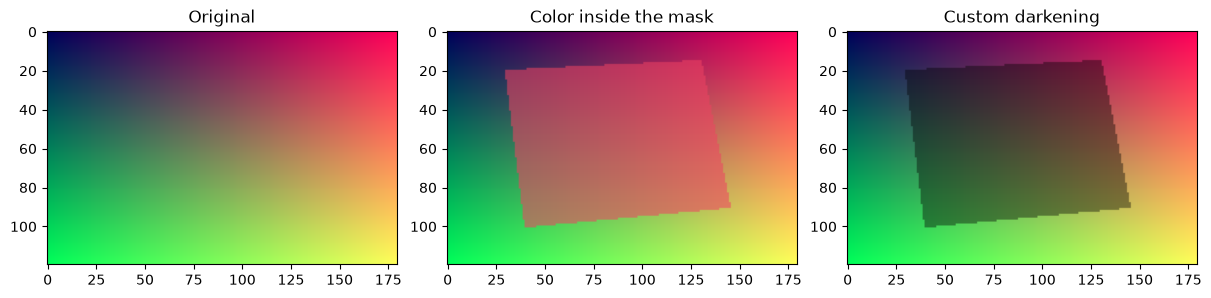

In [4]:
tinted = image.copy().implant_filter(Filter('#f04262', ratio=.7), heat)
custom = Filter().set_function(lambda pixels, weight: pixels * (1 - .5 * weight))
darkened = image.copy().implant_filter(custom, heat)
debugger.log_images(
    [image.get_image(), tinted.get_image(), darkened.get_image()],
    ['Original', 'Color inside the mask', 'Custom darkening'],
    [Debugger.LogTypes.IMAGE] * 3,
);

## Checks

In [5]:
assert heat.shape == image.shape
assert np.allclose((heat - other).get_heat(), np.minimum(heat.get_heat(), other.get_heat()))
assert np.array_equal(tinted.get_image()[0, 0], image.get_image()[0, 0])
assert not np.array_equal(tinted.get_image()[50, 70], image.get_image()[50, 70])

## Take it further 🚀

We can place a color effect. Next, learn how to keep an edit while retracing geometry—and how to discard it with undo.

[Choose the next notebook](https://github.com/bateni1380/landpy/tree/master/tutorials)

**Try it:** Set the filter ratio to 0, then 1. What does a mask value of 0.8 allow?

➡️ **[Continue to notebook 4](https://github.com/bateni1380/landpy/blob/master/tutorials/4-history-and-debugging.ipynb)**

[← Previous lesson](https://github.com/bateni1380/landpy/blob/master/tutorials/2-landmarks-and-regions.ipynb)